# MultispeQ device-bias validation

This notebook asks five related questions for the published Fig. 4 C/D subset:

1. **Is there evidence of systematic differences among the four MultispeQ devices after accounting for plant, date, time of day, and light level?**
2. **Do the biological conclusions for re-fitted ECSt and NPQt change when device is included in the statistical model?**
3. **Are device-adjusted and unadjusted biological contrasts practically equivalent at pre-specified margins?**
4. **Are the conclusions retained when Control and Drought are compared only on concurrent dates?**
5. **Does device-associated variation remain when comparisons are made within the same plant and date?**

The analysis is observational rather than a calibration experiment. Device and date are partly confounded, so raw device means are not interpreted as instrument bias. Device offsets are estimated from repeated measurements within plants, with date, time of day, and PAR included as nuisance variables. Biological contrasts use plant-clustered standard errors and Benjamini–Hochberg false-discovery-rate correction.

In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from patsy import build_design_matrices
from scipy.stats import norm

sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "processed" / "ecs_refit.parquet"
OUTPUT_DIR = ROOT / "outputs"
PROCESSED_DIR = ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


## Data and identifiability

The same published filters used for Fig. 4 C/D are applied here. A plant cluster is defined by genotype, treatment, and replicate number. Date and time are derived from the UTC timestamp; the absolute timezone does not affect the within-day adjustment.

In [2]:
df = pd.read_parquet(DATA_PATH)
timestamp = pd.to_datetime(df["timestamp"], utc=True)
df["date"] = timestamp.dt.strftime("%Y-%m-%d")
df["hour"] = timestamp.dt.hour + timestamp.dt.minute / 60 + timestamp.dt.second / 3600
df["hour_centered"] = df["hour"] - df["hour"].mean()
df["hour_centered_sq"] = df["hour_centered"] ** 2
df["log_PAR"] = np.log1p(df["PAR"].astype(float))
df["plant_id"] = (
    df["which_plant"].astype(str)
    + "|" + df["condition"].astype(str)
    + "|" + df["rep"].astype(str)
)

analysis = df.loc[
    (df["PAR"] > 0)
    & df["ECSt_calc"].between(0, 0.004)
    & df["NPQt"].between(0, 5)
    & df["which_plant"].isin(["W", "p1", "p2"])
    & df["condition"].isin(["Con", "Dr"])
].copy()

category_orders = {
    "which_plant": ["W", "p1", "p2"],
    "condition": ["Con", "Dr"],
    "date": sorted(analysis["date"].unique()),
    "device_id": sorted(analysis["device_id"].unique()),
    "plant_id": sorted(analysis["plant_id"].unique()),
}
for column, categories in category_orders.items():
    analysis[column] = pd.Categorical(analysis[column], categories=categories)

expected_counts = {
    ("W", "Con"): 106, ("W", "Dr"): 86,
    ("p1", "Con"): 103, ("p1", "Dr"): 87,
    ("p2", "Con"): 97, ("p2", "Dr"): 86,
}
observed_counts = analysis.groupby(
    ["which_plant", "condition"], observed=True
).size().to_dict()
assert observed_counts == expected_counts
assert analysis[["ECSt_calc", "NPQt", "device_id", "plant_id"]].notna().all().all()

device_by_date = pd.crosstab(analysis["device_id"], analysis["date"])
devices_per_plant = analysis.groupby("plant_id", observed=True)["device_id"].nunique()
all_date_devices = device_by_date.index[(device_by_date > 0).all(axis=1)].tolist()

display(pd.DataFrame({
    "measurements": [len(analysis)],
    "plant clusters": [analysis["plant_id"].nunique()],
    "devices": [analysis["device_id"].nunique()],
    "plants measured by ≥2 devices": [(devices_per_plant >= 2).sum()],
    "devices present on every date": [len(all_date_devices)],
}))
display(device_by_date)
print("Devices present on every date:", ", ".join(all_date_devices))


,measurements,plant clusters,devices,plants measured by ≥2 devices,devices present on every date
0,565,69,4,68,2


date,2022-07-21,2022-07-22,2022-07-28
device_id,,,
01:12:37:34,70,44,64
01:12:52:49,0,0,90
41:00:08:81,34,0,0
52:00:08:b1,100,50,113


Devices present on every date: 01:12:37:34, 52:00:08:b1


## Models

Two models are used for each outcome.

- **Within-plant bias model:** plant fixed effects absorb stable biological differences. Date, a quadratic time-of-day term, and log(PAR) are nuisance covariates. Adding device tests whether device explains residual variation and yields centred device offsets for visualization.
- **Biological conclusion model:** genotype × treatment is the target term. The unadjusted and device-aware versions both control date, time of day, and PAR; the latter additionally contains device. Standard errors are clustered by plant.

The device-aware model is the inferential adjustment. Subtracting the estimated offsets creates intuitive adjusted values for plots, but those values alone would ignore uncertainty in the estimated offsets.

In [3]:
OUTCOMES = {
    "ECSt_calc": "Re-fitted ECSt",
    "NPQt": "NPQt",
}

NUISANCE = "C(date) + log_PAR + hour_centered + hour_centered_sq"
BIOLOGICAL = (
    "C(which_plant, Treatment(reference='W'))"
    " * C(condition, Treatment(reference='Con'))"
    f" + {NUISANCE}"
)

CONTRASTS = [
    ("Dr − Con within W", ("W", "Dr"), ("W", "Con")),
    ("Dr − Con within p1", ("p1", "Dr"), ("p1", "Con")),
    ("Dr − Con within p2", ("p2", "Dr"), ("p2", "Con")),
    ("p1 − W within Con", ("p1", "Con"), ("W", "Con")),
    ("p2 − W within Con", ("p2", "Con"), ("W", "Con")),
    ("p1 − W within Dr", ("p1", "Dr"), ("W", "Dr")),
    ("p2 − W within Dr", ("p2", "Dr"), ("W", "Dr")),
]

def fit_clustered(data, formula):
    return smf.ols(formula, data=data).fit(
        cov_type="cluster",
        cov_kwds={"groups": np.asarray(data["plant_id"]), "use_correction": True},
    )

def design_matrix(result, new_data):
    design_info = result.model.data.orig_exog.design_info
    return np.asarray(build_design_matrices([design_info], new_data)[0])

def as_float(value):
    return float(np.asarray(value).squeeze())

def linear_estimate(result, vector):
    params = result.params.to_numpy()
    covariance = result.cov_params().to_numpy()
    estimate = float(vector @ params)
    standard_error = float(np.sqrt(vector @ covariance @ vector))
    z_value = estimate / standard_error
    p_value = float(2 * norm.sf(abs(z_value)))
    return estimate, standard_error, p_value

def bh_adjust(values):
    p = np.asarray(values, dtype=float)
    order = np.argsort(p)
    ranked = p[order] * len(p) / np.arange(1, len(p) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    adjusted = np.empty_like(ranked)
    adjusted[order] = np.minimum(ranked, 1)
    return adjusted

def marginal_vector(result, data, genotype, condition):
    uses_device = "C(device_id)" in result.model.formula
    devices = list(data["device_id"].cat.categories) if uses_device else [None]
    rows = []
    for date, device in product(data["date"].cat.categories, devices):
        row = {
            "which_plant": genotype,
            "condition": condition,
            "date": date,
            "log_PAR": data["log_PAR"].median(),
            "hour_centered": 0.0,
            "hour_centered_sq": 0.0,
        }
        if device is not None:
            row["device_id"] = device
        rows.append(row)
    grid = pd.DataFrame(rows)
    for column in ["which_plant", "condition", "date", "device_id"]:
        if column in grid:
            grid[column] = pd.Categorical(
                grid[column], categories=data[column].cat.categories
            )
    return design_matrix(result, grid).mean(axis=0)

def contrast_table(result, data, outcome, model_name):
    rows = []
    for label, positive, negative in CONTRASTS:
        vector = (
            marginal_vector(result, data, *positive)
            - marginal_vector(result, data, *negative)
        )
        estimate, standard_error, p_value = linear_estimate(result, vector)
        rows.append({
            "outcome": outcome,
            "model": model_name,
            "contrast": label,
            "estimate": estimate,
            "standard_error": standard_error,
            "ci_low": estimate - 1.96 * standard_error,
            "ci_high": estimate + 1.96 * standard_error,
            "p_value": p_value,
        })
    result_table = pd.DataFrame(rows)
    result_table["q_value"] = bh_adjust(result_table["p_value"])
    return result_table


In [4]:
device_summary_rows = []
device_offset_rows = []
contrast_tables = []
models = {}
adjusted_values = analysis.copy()

for outcome, outcome_label in OUTCOMES.items():
    # Within-plant device-bias model.
    bias_reduced = fit_clustered(
        analysis, f"{outcome} ~ C(plant_id) + {NUISANCE}"
    )
    bias_full = fit_clustered(
        analysis, f"{outcome} ~ C(plant_id) + {NUISANCE} + C(device_id)"
    )
    device_term_indices = [
        index for index, name in enumerate(bias_full.params.index)
        if name.startswith("C(device_id)")
    ]
    restriction = np.eye(len(bias_full.params))[device_term_indices]
    device_test = bias_full.f_test(restriction)
    partial_r2 = (bias_reduced.ssr - bias_full.ssr) / bias_reduced.ssr
    device_summary_rows.append({
        "outcome": outcome,
        "label": outcome_label,
        "device_F": as_float(device_test.fvalue),
        "device_df_num": as_float(device_test.df_num),
        "device_df_den": as_float(device_test.df_denom),
        "device_p_value": as_float(device_test.pvalue),
        "partial_r2": partial_r2,
    })

    # Counterfactual predictions centre every device against the equal-device mean.
    device_vectors = {}
    for device in analysis["device_id"].cat.categories:
        counterfactual = analysis.copy()
        counterfactual["device_id"] = pd.Categorical(
            [device] * len(counterfactual),
            categories=analysis["device_id"].cat.categories,
        )
        device_vectors[device] = design_matrix(bias_full, counterfactual).mean(axis=0)
    grand_device_vector = np.mean(list(device_vectors.values()), axis=0)
    offsets = {}
    for device, vector in device_vectors.items():
        offset_vector = vector - grand_device_vector
        estimate, standard_error, p_value = linear_estimate(bias_full, offset_vector)
        offsets[device] = estimate
        device_offset_rows.append({
            "outcome": outcome,
            "device_id": device,
            "offset": estimate,
            "standard_error": standard_error,
            "ci_low": estimate - 1.96 * standard_error,
            "ci_high": estimate + 1.96 * standard_error,
            "p_value": p_value,
        })
    adjusted_values[f"{outcome}_device_adjusted"] = (
        analysis[outcome] - analysis["device_id"].astype(str).map(offsets)
    )

    # Biological models: same target contrasts, with and without device.
    unadjusted = fit_clustered(analysis, f"{outcome} ~ {BIOLOGICAL}")
    device_aware = fit_clustered(
        analysis, f"{outcome} ~ {BIOLOGICAL} + C(device_id)"
    )
    models[outcome] = {"unadjusted": unadjusted, "device_aware": device_aware}
    contrast_tables.extend([
        contrast_table(unadjusted, analysis, outcome, "unadjusted"),
        contrast_table(device_aware, analysis, outcome, "device_aware"),
    ])

device_summary = pd.DataFrame(device_summary_rows)
device_offsets = pd.DataFrame(device_offset_rows)
contrasts = pd.concat(contrast_tables, ignore_index=True)

unadjusted_contrasts = contrasts.loc[contrasts["model"] == "unadjusted"].drop(
    columns="model"
).add_suffix("_unadjusted")
device_aware_contrasts = contrasts.loc[contrasts["model"] == "device_aware"].drop(
    columns="model"
).add_suffix("_device_aware")
contrast_comparison = unadjusted_contrasts.merge(
    device_aware_contrasts,
    left_on=["outcome_unadjusted", "contrast_unadjusted"],
    right_on=["outcome_device_aware", "contrast_device_aware"],
)
contrast_comparison["significant_unadjusted"] = (
    contrast_comparison["q_value_unadjusted"] < 0.05
)
contrast_comparison["significant_device_aware"] = (
    contrast_comparison["q_value_device_aware"] < 0.05
)
contrast_comparison["significance_changed"] = (
    contrast_comparison["significant_unadjusted"]
    != contrast_comparison["significant_device_aware"]
)
contrast_comparison["direction_changed"] = (
    np.sign(contrast_comparison["estimate_unadjusted"])
    != np.sign(contrast_comparison["estimate_device_aware"])
)
for model_name, indices in contrasts.groupby("model").groups.items():
    contrasts.loc[indices, "q_value_all14"] = bh_adjust(
        contrasts.loc[indices, "p_value"]
    )

contrast_comparison["relative_effect_change_pct"] = (
    100
    * (contrast_comparison["estimate_device_aware"] - contrast_comparison["estimate_unadjusted"])
    / contrast_comparison["estimate_unadjusted"].abs()
)


## Date-confounding sensitivity check

The primary model controls date, but two devices occur on only one date. As a stricter sensitivity analysis, the biological models are repeated using only devices observed on every measurement date. This retains the cross-date bridge and removes the single-date devices.

In [5]:
sensitivity_data = analysis.loc[analysis["device_id"].isin(all_date_devices)].copy()
sensitivity_data["device_id"] = sensitivity_data["device_id"].cat.remove_unused_categories()
sensitivity_tables = []
for outcome in OUTCOMES:
    for model_name, formula in [
        ("unadjusted", f"{outcome} ~ {BIOLOGICAL}"),
        ("device_aware", f"{outcome} ~ {BIOLOGICAL} + C(device_id)"),
    ]:
        fitted = fit_clustered(sensitivity_data, formula)
        sensitivity_tables.append(
            contrast_table(fitted, sensitivity_data, outcome, model_name)
        )
sensitivity_contrasts = pd.concat(sensitivity_tables, ignore_index=True)

display(Markdown(
    f"Sensitivity subset: **{len(sensitivity_data)} measurements**, "
    f"**{sensitivity_data['plant_id'].nunique()} plant clusters**, and devices "
    f"`{'`, `'.join(all_date_devices)}`."
))


Sensitivity subset: **441 measurements**, **69 plant clusters**, and devices `01:12:37:34`, `52:00:08:b1`.

## Formal equivalence of biological contrasts

A paired cluster bootstrap now tests the quantity that matters directly: the change in each biological contrast after adding device to the model. Whole plants are resampled within genotype × treatment strata, and the unadjusted and device-aware models are fitted to the same resample. The pre-specified primary margin is 0.10 pooled SD; 0.20 SD is a secondary small-effect margin.

In [6]:
FROZEN_SD = {"ECSt_calc": 0.0005891359446399744, "NPQt": 0.8466020243031155}
PRIMARY_MARGIN_SD = 0.10
SECONDARY_MARGIN_SD = 0.20
N_BOOTSTRAP = 5000
BOOTSTRAP_SEED = 20260922

for outcome, frozen_sd in FROZEN_SD.items():
    assert np.isclose(analysis[outcome].std(), frozen_sd, rtol=0, atol=1e-12)

bootstrap_specs = {}
for outcome in OUTCOMES:
    bootstrap_specs[outcome] = {}
    for model_name, result in models[outcome].items():
        contrast_vectors = np.vstack([
            marginal_vector(result, analysis, *positive)
            - marginal_vector(result, analysis, *negative)
            for _, positive, negative in CONTRASTS
        ])
        bootstrap_specs[outcome][model_name] = {
            "x": np.asarray(result.model.exog),
            "y": analysis[outcome].to_numpy(),
            "vectors": contrast_vectors,
        }

plant_frame = analysis[["plant_id", "which_plant", "condition"]].drop_duplicates()
plant_strata = [
    group["plant_id"].astype(str).tolist()
    for _, group in plant_frame.groupby(["which_plant", "condition"], observed=True)
]
row_plants = analysis["plant_id"].astype(str).to_numpy()
bootstrap_estimates = {
    (outcome, model_name): np.full((N_BOOTSTRAP, len(CONTRASTS)), np.nan)
    for outcome in OUTCOMES for model_name in ["unadjusted", "device_aware"]
}
rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_failures = 0

for bootstrap_index in range(N_BOOTSTRAP):
    plant_counts = {}
    for plants in plant_strata:
        counts = rng.multinomial(len(plants), np.repeat(1 / len(plants), len(plants)))
        plant_counts.update(dict(zip(plants, counts)))
    row_weights = np.fromiter(
        (plant_counts[plant] for plant in row_plants), dtype=float, count=len(row_plants)
    )
    sqrt_weights = np.sqrt(row_weights)
    failed = False
    for outcome in OUTCOMES:
        for model_name in ["unadjusted", "device_aware"]:
            spec = bootstrap_specs[outcome][model_name]
            beta, _, rank, _ = np.linalg.lstsq(
                spec["x"] * sqrt_weights[:, None],
                spec["y"] * sqrt_weights,
                rcond=None,
            )
            if rank < spec["x"].shape[1]:
                failed = True
                break
            bootstrap_estimates[(outcome, model_name)][bootstrap_index] = (
                spec["vectors"] @ beta
            )
        if failed:
            break
    if failed:
        bootstrap_failures += 1
        for estimates in bootstrap_estimates.values():
            estimates[bootstrap_index] = np.nan

bootstrap_success_rate = 1 - bootstrap_failures / N_BOOTSTRAP
assert bootstrap_success_rate >= 0.99

equivalence_rows = []
for outcome in OUTCOMES:
    bootstrap_delta = (
        bootstrap_estimates[(outcome, "device_aware")]
        - bootstrap_estimates[(outcome, "unadjusted")]
    )
    primary_margin = PRIMARY_MARGIN_SD * FROZEN_SD[outcome]
    secondary_margin = SECONDARY_MARGIN_SD * FROZEN_SD[outcome]
    for contrast_index, (contrast_label, _, _) in enumerate(CONTRASTS):
        observed = contrast_comparison.loc[
            (contrast_comparison["outcome_unadjusted"] == outcome)
            & (contrast_comparison["contrast_unadjusted"] == contrast_label)
        ].iloc[0]
        values = bootstrap_delta[:, contrast_index]
        ci90_low, ci90_high = np.nanpercentile(values, [5, 95])
        ci95_low, ci95_high = np.nanpercentile(values, [2.5, 97.5])
        if ci90_low > -primary_margin and ci90_high < primary_margin:
            status = "equivalent_0.10_sd"
        elif ci90_low > -secondary_margin and ci90_high < secondary_margin:
            status = "equivalent_0.20_sd_only"
        else:
            status = "inconclusive"
        delta = observed["estimate_device_aware"] - observed["estimate_unadjusted"]
        equivalence_rows.append({
            "outcome": outcome,
            "contrast": contrast_label,
            "estimate_unadjusted": observed["estimate_unadjusted"],
            "estimate_device_aware": observed["estimate_device_aware"],
            "delta": delta,
            "delta_sd": delta / FROZEN_SD[outcome],
            "ci90_low": ci90_low,
            "ci90_high": ci90_high,
            "ci95_low": ci95_low,
            "ci95_high": ci95_high,
            "primary_margin": primary_margin,
            "secondary_margin": secondary_margin,
            "equivalence_status": status,
            "bootstrap_successes": int(np.isfinite(values).sum()),
            "bootstrap_failures": bootstrap_failures,
        })
equivalence = pd.DataFrame(equivalence_rows)
assert len(equivalence) == 14

display(Markdown(
    f"Bootstrap success rate: **{100 * bootstrap_success_rate:.2f}%** "
    f"({N_BOOTSTRAP - bootstrap_failures:,}/{N_BOOTSTRAP:,} replicates)."
))
display(equivalence[["outcome", "contrast", "delta_sd", "ci90_low", "ci90_high", "equivalence_status"]])


Bootstrap success rate: **100.00%** (5,000/5,000 replicates).

,outcome,contrast,delta_sd,ci90_low,ci90_high,equivalence_status
0,ECSt_calc,Dr − Con within W,-0.031509,-0.000045,0.000009,equivalent_0.10_sd
1,ECSt_calc,Dr − Con within p1,-0.006454,-0.000028,0.000023,equivalent_0.10_sd
2,ECSt_calc,Dr − Con within p2,-0.048769,-0.000053,-0.000001,equivalent_0.10_sd
3,ECSt_calc,p1 − W within Con,-0.010002,-0.000034,0.000020,equivalent_0.10_sd
4,ECSt_calc,p2 − W within Con,0.006028,-0.000023,0.000028,equivalent_0.10_sd
5,ECSt_calc,p1 − W within Dr,0.015052,-0.000011,0.000029,equivalent_0.10_sd
6,ECSt_calc,p2 − W within Dr,-0.011232,-0.000026,0.000015,equivalent_0.10_sd
7,NPQt,Dr − Con within W,-0.092031,-0.135982,-0.025895,equivalent_0.20_sd_only
8,NPQt,Dr − Con within p1,-0.058513,-0.108229,0.006667,equivalent_0.20_sd_only
9,NPQt,Dr − Con within p2,-0.066601,-0.122530,0.006359,equivalent_0.20_sd_only


## Matched-date longitudinal sensitivity

The reference analysis reproduces the published subset, in which Control also includes 22 July while Drought does not. This sensitivity analysis uses only 21 and 28 July, fits genotype × treatment × date, and reports both equally averaged and date-specific contrasts.

In [7]:
MATCHED_DATES = ["2022-07-21", "2022-07-28"]
matched_data = analysis.loc[analysis["date"].isin(MATCHED_DATES)].copy()
matched_data["date"] = matched_data["date"].cat.remove_unused_categories()
assert len(matched_data) == 471

MATCHED_BIOLOGICAL = (
    "C(which_plant, Treatment(reference='W'))"
    " * C(condition, Treatment(reference='Con'))"
    " * C(date) + log_PAR + hour_centered + hour_centered_sq"
)

def marginal_vector_dates(result, data, genotype, condition, dates):
    uses_device = "C(device_id)" in result.model.formula
    devices = list(data["device_id"].cat.categories) if uses_device else [None]
    rows = []
    for date, device in product(dates, devices):
        row = {
            "which_plant": genotype, "condition": condition, "date": date,
            "log_PAR": data["log_PAR"].median(),
            "hour_centered": 0.0, "hour_centered_sq": 0.0,
        }
        if device is not None:
            row["device_id"] = device
        rows.append(row)
    grid = pd.DataFrame(rows)
    for column in ["which_plant", "condition", "date", "device_id"]:
        if column in grid:
            grid[column] = pd.Categorical(grid[column], categories=data[column].cat.categories)
    return design_matrix(result, grid).mean(axis=0)

def contrast_table_dates(result, data, outcome, model_name, dates, date_scope):
    rows = []
    for label, positive, negative in CONTRASTS:
        vector = (
            marginal_vector_dates(result, data, *positive, dates)
            - marginal_vector_dates(result, data, *negative, dates)
        )
        estimate, standard_error, p_value = linear_estimate(result, vector)
        rows.append({
            "outcome": outcome, "model": model_name, "date_scope": date_scope,
            "contrast": label, "estimate": estimate,
            "standard_error": standard_error,
            "ci_low": estimate - 1.96 * standard_error,
            "ci_high": estimate + 1.96 * standard_error,
            "p_value": p_value,
        })
    table = pd.DataFrame(rows)
    table["q_value"] = bh_adjust(table["p_value"])
    return table

matched_tables = []
matched_summary_rows = []
matched_models = {}
for outcome in OUTCOMES:
    matched_models[outcome] = {}
    for model_name, device_term in [("unadjusted", ""), ("device_aware", " + C(device_id)")]:
        fitted = fit_clustered(matched_data, f"{outcome} ~ {MATCHED_BIOLOGICAL}{device_term}")
        matched_models[outcome][model_name] = fitted
        matched_tables.append(contrast_table_dates(
            fitted, matched_data, outcome, model_name, MATCHED_DATES, "pooled"
        ))
        for date in MATCHED_DATES:
            matched_tables.append(contrast_table_dates(
                fitted, matched_data, outcome, model_name, [date], date
            ))
        interaction_indices = [
            index for index, name in enumerate(fitted.params.index)
            if "C(which_plant" in name and "C(condition" in name and ":C(date)" in name
        ]
        interaction_test = fitted.f_test(np.eye(len(fitted.params))[interaction_indices])
        matched_summary_rows.append({
            "outcome": outcome, "model": model_name,
            "interaction_F": as_float(interaction_test.fvalue),
            "interaction_df_num": as_float(interaction_test.df_num),
            "interaction_df_den": as_float(interaction_test.df_denom),
            "interaction_p_value": as_float(interaction_test.pvalue),
        })
matched_contrasts = pd.concat(matched_tables, ignore_index=True)
matched_summary = pd.DataFrame(matched_summary_rows)
for _, indices in matched_contrasts.groupby(["model", "date_scope"]).groups.items():
    matched_contrasts.loc[indices, "q_value_all14"] = bh_adjust(
        matched_contrasts.loc[indices, "p_value"]
    )

reference_for_match = contrasts.rename(columns={
    "estimate": "estimate_reference", "q_value": "q_value_reference",
    "q_value_all14": "q_value_all14_reference",
})[["outcome", "model", "contrast", "estimate_reference", "q_value_reference", "q_value_all14_reference"]]
matched_pooled = matched_contrasts.loc[matched_contrasts["date_scope"] == "pooled"].rename(columns={
    "estimate": "estimate_matched", "q_value": "q_value_matched",
    "q_value_all14": "q_value_all14_matched",
})
matched_comparison = reference_for_match.merge(
    matched_pooled[["outcome", "model", "contrast", "estimate_matched", "q_value_matched", "q_value_all14_matched"]],
    on=["outcome", "model", "contrast"],
)
matched_comparison["change_sd"] = (
    matched_comparison["estimate_matched"] - matched_comparison["estimate_reference"]
) / matched_comparison["outcome"].map(FROZEN_SD)
matched_comparison["direction_changed"] = (
    np.sign(matched_comparison["estimate_matched"])
    != np.sign(matched_comparison["estimate_reference"])
)
matched_comparison["fdr_changed"] = (
    (matched_comparison["q_value_matched"] < 0.05)
    != (matched_comparison["q_value_reference"] < 0.05)
)
assert len(matched_comparison) == 28
display(matched_summary)
display(matched_comparison.loc[matched_comparison["model"] == "device_aware"])


,outcome,model,interaction_F,interaction_df_num,interaction_df_den,interaction_p_value
0,ECSt_calc,unadjusted,0.530977,2.0,68.0,0.590448
1,ECSt_calc,device_aware,0.526484,2.0,68.0,0.593066
2,NPQt,unadjusted,2.182288,2.0,68.0,0.120620
3,NPQt,device_aware,3.877600,2.0,68.0,0.025426


,outcome,model,contrast,estimate_reference,q_value_reference,q_value_all14_reference,estimate_matched,q_value_matched,q_value_all14_matched,change_sd,direction_changed,fdr_changed
7,ECSt_calc,device_aware,Dr − Con within W,-0.000393,7.602813e-09,3.801406e-09,-0.000439,2.811866e-12,1.874577e-12,-0.079457,False,False
8,ECSt_calc,device_aware,Dr − Con within p1,-0.000282,4.453635e-04,4.453635e-04,-0.000246,1.266435e-03,1.266435e-03,0.060773,False,False
9,ECSt_calc,device_aware,Dr − Con within p2,-0.000111,1.737960e-01,1.737960e-01,-0.000154,4.760181e-02,4.327437e-02,-0.072885,False,True
10,ECSt_calc,device_aware,p1 − W within Con,-0.000237,1.199968e-04,1.028544e-04,-0.000294,4.617965e-08,4.617965e-08,-0.097279,False,False
11,ECSt_calc,device_aware,p2 − W within Con,-0.000344,1.289241e-06,8.594943e-07,-0.000372,1.889951e-08,1.511961e-08,-0.048656,False,False
12,ECSt_calc,device_aware,p1 − W within Dr,-0.000127,1.514955e-01,1.377232e-01,-0.000101,1.939459e-01,2.021617e-01,0.042952,False,False
13,ECSt_calc,device_aware,p2 − W within Dr,-0.000062,4.051968e-01,4.363658e-01,-0.000087,1.939459e-01,2.068515e-01,-0.042083,False,False
21,NPQt,device_aware,Dr − Con within W,-0.545758,1.080879e-10,2.161757e-10,-0.589331,8.104363e-10,1.215654e-09,-0.051469,False,False
22,NPQt,device_aware,Dr − Con within p1,-0.918317,6.815223e-50,1.363045e-49,-0.865453,8.180044e-54,1.636009e-53,0.062443,False,False
23,NPQt,device_aware,Dr − Con within p2,-0.734950,1.249288e-29,2.498576e-29,-0.729449,1.028458e-28,2.056916e-28,0.006498,False,False


## Within-plant-date device model

This stricter device model compares instruments within the same plant's same-day session. A bridge-device interaction check then asks whether the relative offset between the two devices used on every date is stable across dates.

In [8]:
session_source = analysis.copy()
session_source["plant_date"] = (
    session_source["plant_id"].astype(str) + "|" + session_source["date"].astype(str)
)
devices_per_session = session_source.groupby("plant_date")["device_id"].nunique()
eligible_sessions = devices_per_session.index[devices_per_session >= 2]
session_data = session_source.loc[session_source["plant_date"].isin(eligible_sessions)].copy()
session_data["plant_date"] = pd.Categorical(
    session_data["plant_date"], categories=sorted(session_data["plant_date"].unique())
)
assert len(session_data) == 496
assert session_data["plant_date"].nunique() == 147

session_summary_rows = []
session_offset_rows = []
for outcome in OUTCOMES:
    session_reduced = fit_clustered(
        session_data,
        f"{outcome} ~ C(plant_date) + log_PAR + hour_centered + hour_centered_sq",
    )
    session_full = fit_clustered(
        session_data,
        f"{outcome} ~ C(plant_date) + log_PAR + hour_centered + hour_centered_sq + C(device_id)",
    )
    device_indices = [
        index for index, name in enumerate(session_full.params.index)
        if name.startswith("C(device_id)")
    ]
    device_test = session_full.f_test(np.eye(len(session_full.params))[device_indices])
    session_summary_rows.append({
        "outcome": outcome,
        "device_F": as_float(device_test.fvalue),
        "device_df_num": as_float(device_test.df_num),
        "device_df_den": as_float(device_test.df_denom),
        "device_p_value": as_float(device_test.pvalue),
        "partial_r2": (session_reduced.ssr - session_full.ssr) / session_reduced.ssr,
    })
    device_vectors = {}
    for device in session_data["device_id"].cat.categories:
        counterfactual = session_data.copy()
        counterfactual["device_id"] = pd.Categorical(
            [device] * len(counterfactual), categories=session_data["device_id"].cat.categories
        )
        device_vectors[device] = design_matrix(session_full, counterfactual).mean(axis=0)
    grand_vector = np.mean(list(device_vectors.values()), axis=0)
    for device, vector in device_vectors.items():
        estimate, standard_error, p_value = linear_estimate(session_full, vector - grand_vector)
        session_offset_rows.append({
            "outcome": outcome, "device_id": device, "offset": estimate,
            "standard_error": standard_error,
            "ci_low": estimate - 1.96 * standard_error,
            "ci_high": estimate + 1.96 * standard_error,
            "p_value": p_value,
        })
session_summary = pd.DataFrame(session_summary_rows)
session_offsets = pd.DataFrame(session_offset_rows)

bridge_data = session_data.loc[session_data["device_id"].isin(all_date_devices)].copy()
bridge_data["device_id"] = bridge_data["device_id"].cat.remove_unused_categories()
bridge_counts = bridge_data.groupby("plant_date", observed=True)["device_id"].nunique()
bridge_sessions = bridge_counts.index[bridge_counts >= 2]
bridge_data = bridge_data.loc[bridge_data["plant_date"].isin(bridge_sessions)].copy()
bridge_data["plant_date"] = bridge_data["plant_date"].cat.remove_unused_categories()
assert len(bridge_data) == 299
assert bridge_data["plant_date"].nunique() == 107
bridge_data["bridge_device"] = (
    bridge_data["device_id"].astype(str) == all_date_devices[1]
).astype(float)
bridge_data["bridge_device_x_22"] = bridge_data["bridge_device"] * (
    bridge_data["date"].astype(str) == "2022-07-22"
).astype(float)
bridge_data["bridge_device_x_28"] = bridge_data["bridge_device"] * (
    bridge_data["date"].astype(str) == "2022-07-28"
).astype(float)
bridge_rows = []
for outcome in OUTCOMES:
    bridge_fit = fit_clustered(
        bridge_data,
        f"{outcome} ~ C(plant_date) + log_PAR + hour_centered + hour_centered_sq"
        " + bridge_device + bridge_device_x_22 + bridge_device_x_28",
    )
    interaction_test = bridge_fit.f_test(
        "bridge_device_x_22 = 0, bridge_device_x_28 = 0"
    )
    bridge_rows.append({
        "outcome": outcome,
        "reference_device": all_date_devices[0],
        "comparison_device": all_date_devices[1],
        "offset_2022_07_21": bridge_fit.params["bridge_device"],
        "offset_change_2022_07_22": bridge_fit.params["bridge_device_x_22"],
        "offset_change_2022_07_28": bridge_fit.params["bridge_device_x_28"],
        "interaction_F": as_float(interaction_test.fvalue),
        "interaction_df_num": as_float(interaction_test.df_num),
        "interaction_df_den": as_float(interaction_test.df_denom),
        "interaction_p_value": as_float(interaction_test.pvalue),
    })
bridge_stability = pd.DataFrame(bridge_rows)
display(session_summary)
display(bridge_stability)


,outcome,device_F,device_df_num,device_df_den,device_p_value,partial_r2
0,ECSt_calc,14.011504,3.0,67.0,3.448544e-07,0.120543
1,NPQt,25.325809,3.0,67.0,4.570825e-11,0.161002


,outcome,reference_device,comparison_device,offset_2022_07_21,offset_change_2022_07_22,offset_change_2022_07_28,interaction_F,interaction_df_num,interaction_df_den,interaction_p_value
0,ECSt_calc,01:12:37:34,52:00:08:b1,0.000322,-0.000086,-0.000379,4.269131,2.0,61.0,0.018396
1,NPQt,01:12:37:34,52:00:08:b1,-0.515629,0.508625,0.134750,3.575426,2.0,61.0,0.034016


In [9]:
summary_view = device_summary[[
    "label", "device_F", "device_df_num", "device_df_den",
    "device_p_value", "partial_r2",
]].copy()
summary_view["partial_r2"] *= 100
summary_view = summary_view.rename(columns={"partial_r2": "partial R² (%)"})
display(summary_view.style.format({
    "device_F": "{:.2f}", "device_p_value": "{:.3g}", "partial R² (%)": "{:.1f}"
}))

display(contrast_comparison[[
    "outcome_unadjusted", "contrast_unadjusted",
    "estimate_unadjusted", "q_value_unadjusted",
    "estimate_device_aware", "q_value_device_aware",
    "relative_effect_change_pct", "significance_changed", "direction_changed",
]].style.format({
    "estimate_unadjusted": "{:.6g}", "estimate_device_aware": "{:.6g}",
    "q_value_unadjusted": "{:.3g}", "q_value_device_aware": "{:.3g}",
    "relative_effect_change_pct": "{:+.1f}",
}))

primary_flips = int(contrast_comparison["significance_changed"].sum())
primary_direction_flips = int(contrast_comparison["direction_changed"].sum())

sensitivity_wide = sensitivity_contrasts.pivot(
    index=["outcome", "contrast"], columns="model", values="q_value"
).reset_index()
sensitivity_flips = int(
    ((sensitivity_wide["unadjusted"] < 0.05)
     != (sensitivity_wide["device_aware"] < 0.05)).sum()
)
equivalence_counts = equivalence["equivalence_status"].value_counts()
primary_equivalent = int(equivalence_counts.get("equivalent_0.10_sd", 0))
secondary_only = int(equivalence_counts.get("equivalent_0.20_sd_only", 0))
equivalence_inconclusive = int(equivalence_counts.get("inconclusive", 0))
matched_device_aware = matched_comparison.loc[matched_comparison["model"] == "device_aware"]
matched_fdr_flips = int(matched_device_aware["fdr_changed"].sum())
matched_direction_flips = int(matched_device_aware["direction_changed"].sum())

summary_lines = [
    "# MultispeQ device-bias validation for Fig. 4 C/D",
    "",
    "## Question and conclusion",
    "",
    f"Device identity was associated with residual variation in both outcomes, but adding device to the published-subset model changed **{primary_flips} of 14 FDR decisions** and **{primary_direction_flips} contrast directions**. Formal paired-bootstrap equivalence was established at the strict 0.10-SD margin for **{primary_equivalent} contrasts** and at the 0.20-SD margin for the remaining **{secondary_only} contrasts**; **{equivalence_inconclusive} were inconclusive**. The matched-date analysis retained every direction but changed **{matched_fdr_flips} FDR decisions**, so the strongest conclusion is stability of direction and effect scale rather than identical significance calls under every date specification.",
    "",
    "A device term is evidence of device-associated residual structure in this experiment. It is not, by itself, proof of a hardware calibration error because device assignment was not fully randomized and two devices were used on only one date.",
    "",
    "## Data and identifiability",
    "",
    f"The analysis uses the **{len(analysis)} measurements** retained by the published Fig. 4 filters: PAR > 0, 0 ≤ re-fitted ECSt ≤ 0.004, 0 ≤ NPQt ≤ 5, genotypes W/p1/p2, and Control/Drought treatments. These observations represent **{analysis['plant_id'].nunique()} plant clusters** and **{analysis['device_id'].nunique()} devices**. A plant cluster is defined as genotype × treatment × replicate plant. **{(devices_per_plant >= 2).sum()} of {len(devices_per_plant)} plants** were measured by at least two devices, which permits a mostly within-plant device comparison.",
    "",
    "Device allocation was not balanced across dates:",
    "",
    "| MultispeQ device | " + " | ".join(device_by_date.columns.astype(str)) + " |",
    "|---|" + "---:|" * len(device_by_date.columns),
]
for device, counts in device_by_date.iterrows():
    summary_lines.append(
        f"| `{device}` | " + " | ".join(str(int(value)) for value in counts) + " |"
    )
summary_lines.extend([
    "",
    f"Only `{all_date_devices[0]}` and `{all_date_devices[1]}` were present on all three dates. The sensitivity analysis therefore uses those devices only ({len(sensitivity_data)} measurements; {sensitivity_data['plant_id'].nunique()} plant clusters).",
    "",
    "## Statistical methods",
    "",
    "For each outcome, a within-plant model compared a reduced specification (`plant + date + log(PAR) + time + time²`) with a full specification that also included device. Plant fixed effects absorb stable differences among plants. The device term was assessed with a cluster-robust omnibus F test, with standard errors clustered by plant. Partial R² is the proportional reduction in residual sum of squares after adding device.",
    "",
    "Centred device offsets were calculated as equal-device counterfactual predictions from the full within-plant model. They describe model-estimated shifts relative to the mean device, not absolute calibration corrections.",
    "",
    "The biological model estimated genotype × treatment contrasts while controlling for date, log(PAR), and a quadratic time-of-day term. The device-aware version additionally included device identity. Seven pre-specified contrasts were evaluated for each of two outcomes (14 total), using plant-clustered standard errors and Benjamini–Hochberg adjustment within each outcome/model family and, secondarily, across all 14 contrasts. A paired 5,000-replicate plant-cluster bootstrap directly estimated the change caused by device adjustment. Matched-date models added genotype × treatment × date, while the stricter device model used plant × date fixed effects.",
    "",
    "## Device-associated variation",
    "",
    "| Outcome | Omnibus F (df) | p-value | Partial R² | Centred offset range |",
    "|---|---:|---:|---:|---:|",
])
for row in device_summary.itertuples():
    offsets = device_offsets.loc[device_offsets["outcome"] == row.outcome, "offset"]
    summary_lines.append(
        f"| {row.label} | {row.device_F:.2f} ({row.device_df_num:.0f}, {row.device_df_den:.0f}) | {row.device_p_value:.3g} | {100 * row.partial_r2:.1f}% | {offsets.max() - offsets.min():.4g} |"
    )
summary_lines.extend([
    "",
    "The device term explained 10.9% of residual ECSt variation and 13.1% of residual NPQt variation after the within-plant and nuisance controls. Estimated centred offsets were:",
    "",
    "| Outcome | Device | Offset | 95% CI |",
    "|---|---|---:|---:|",
])
for row in device_offsets.itertuples():
    summary_lines.append(
        f"| {OUTCOMES[row.outcome]} | `{row.device_id}` | {row.offset:.6g} | [{row.ci_low:.6g}, {row.ci_high:.6g}] |"
    )
summary_lines.extend([
    "",
    "## Do the biological conclusions change?",
    "",
    f"Across all 14 contrasts, **{primary_flips} changed 5% FDR significance** and **{primary_direction_flips} changed direction** after adding device identity.",
    "",
    "| Outcome | Contrast | Estimate without device | q without device | Estimate with device | q with device | FDR changed? |",
    "|---|---|---:|---:|---:|---:|---|",
])
for row in contrast_comparison.itertuples():
    summary_lines.append(
        f"| {OUTCOMES[row.outcome_unadjusted]} | {row.contrast_unadjusted} | {row.estimate_unadjusted:.6g} | {row.q_value_unadjusted:.3g} | {row.estimate_device_aware:.6g} | {row.q_value_device_aware:.3g} | {'yes' if row.significance_changed else 'no'} |"
    )
summary_lines.extend([
    "",
    "The largest percentage shifts occurred for contrasts whose unadjusted estimates were close to zero, so a small absolute change produces a large relative percentage.",
    "",
    "## Formal equivalence of device-adjusted contrasts",
    "",
    f"All {N_BOOTSTRAP:,} paired plant-cluster bootstrap replicates succeeded. The complete 90% interval for the device-induced change was inside ±0.10 pooled SD for **{primary_equivalent}/14 contrasts**. The other **{secondary_only}/14**—the three NPQt drought-within-genotype contrasts—were equivalent at ±0.20 SD. **{equivalence_inconclusive}/14** were inconclusive at the secondary margin.",
    "",
    "| Outcome | Contrast | Change (SD) | 90% bootstrap interval | Equivalence |",
    "|---|---|---:|---:|---|",
])
for row in equivalence.itertuples():
    equivalence_label = {
        "equivalent_0.10_sd": "equivalent at 0.10 SD",
        "equivalent_0.20_sd_only": "equivalent at 0.20 SD only",
        "inconclusive": "inconclusive",
    }[row.equivalence_status]
    summary_lines.append(
        f"| {OUTCOMES[row.outcome]} | {row.contrast} | {row.delta_sd:+.3f} | [{row.ci90_low / FROZEN_SD[row.outcome]:+.3f}, {row.ci90_high / FROZEN_SD[row.outcome]:+.3f}] SD | {equivalence_label} |"
    )
summary_lines.extend([
    "",
    "## Date and device sensitivity analyses",
    "",
    f"Restricting the reference analysis to the two devices observed on every date produced **{sensitivity_flips} device-adjustment FDR changes**. Restricting Control and Drought to their concurrent dates (21 and 28 July; 471 observations) retained all contrast directions but produced **{matched_fdr_flips} FDR changes** in the device-aware model: p2 ECSt Dr − Con became significant, and p2 − W NPQt within Drought became significant. The device-aware genotype × treatment × date interaction was significant for NPQt (p={matched_summary.loc[(matched_summary['outcome'] == 'NPQt') & (matched_summary['model'] == 'device_aware'), 'interaction_p_value'].iloc[0]:.3g}) but not ECSt.",
    "",
    "The stricter within-plant-date analysis retained 496 observations from 147 sessions. Device remained associated with both outcomes:",
    "",
    "| Outcome | Device omnibus p | Partial R² | Bridge device × date p |",
    "|---|---:|---:|---:|",
])
for row in session_summary.itertuples():
    bridge_p = bridge_stability.loc[bridge_stability["outcome"] == row.outcome, "interaction_p_value"].iloc[0]
    summary_lines.append(
        f"| {OUTCOMES[row.outcome]} | {row.device_p_value:.3g} | {100 * row.partial_r2:.1f}% | {bridge_p:.3g} |"
    )
summary_lines.extend([
    "",
    "The bridge-device interaction was significant for both ECSt and NPQt, indicating that the relative offset between the two devices used on every date was not constant across dates. A single additive correction is therefore an approximation; device should remain in the inferential model rather than treating corrected point values as error-free.",
    "",
    "## Interpretation and limitations",
    "",
    "The reference analysis is robust to adding device: directions and FDR calls are unchanged, and every contrast change is bounded within 0.20 SD. However, only 11 contrasts meet the stricter 0.10-SD criterion, two borderline FDR decisions change in the matched-date specification, NPQt shows date-dependent genotype/treatment structure, and bridge-device offsets vary by date. These results support the broad biological pattern while arguing against a stronger claim that instrument adjustment or date specification is immaterial.",
    "",
    "This is an observational robustness analysis rather than a calibration experiment. Device assignment was unbalanced across dates, environmental covariates may not remove all session effects, and model-estimated offsets are conditional on this experiment and protocol. A dedicated calibration study would randomize devices across the same leaves and reference standards.",
    "",
    "## Reproducibility",
    "",
    "The complete analysis is in [`notebooks/multispeq_device_bias_validation.ipynb`](../notebooks/multispeq_device_bias_validation.ipynb). The main diagnostic is [`device_bias_validation.png`](device_bias_validation.png); machine-readable model summaries, equivalence intervals, matched-date contrasts, offsets and sensitivity results are in the adjacent `device_bias_*.csv` files. The notebook also writes a git-ignored row-level table to `data/processed/fig4_device_adjusted.parquet`.",
])
summary_markdown = "\n".join(summary_lines)
display(Markdown(summary_markdown))


,label,device_F,device_df_num,device_df_den,device_p_value,partial R² (%)
0,Re-fitted ECSt,16.05,3.000000,68.000000,5.42e-08,10.9
1,NPQt,49.00,3.000000,68.000000,5.58e-17,13.1


,outcome_unadjusted,contrast_unadjusted,estimate_unadjusted,q_value_unadjusted,estimate_device_aware,q_value_device_aware,relative_effect_change_pct,significance_changed,direction_changed
0,ECSt_calc,Dr − Con within W,-0.000374003,1.26e-07,-0.000392566,7.6e-09,-5.0,False,False
1,ECSt_calc,Dr − Con within p1,-0.000278439,0.000327,-0.000282241,0.000445,-1.4,False,False
2,ECSt_calc,Dr − Con within p2,-8.20695e-05,0.359,-0.000110801,0.174,-35.0,False,False
3,ECSt_calc,p1 − W within Con,-0.000231089,0.000327,-0.000236982,0.00012,-2.5,False,False
4,ECSt_calc,p2 − W within Con,-0.000347062,9.31e-06,-0.000343511,1.29e-06,+1.0,False,False
5,ECSt_calc,p1 − W within Dr,-0.000135525,0.112,-0.000126657,0.151,+6.5,False,False
6,ECSt_calc,p2 − W within Dr,-5.51286e-05,0.446,-6.17457e-05,0.405,-12.0,False,False
7,NPQt,Dr − Con within W,-0.467844,1.02e-10,-0.545758,1.08e-10,-16.7,False,False
8,NPQt,Dr − Con within p1,-0.86878,1.96e-29,-0.918317,6.82e-50,-5.7,False,False
9,NPQt,Dr − Con within p2,-0.678566,4.92e-28,-0.73495,1.25e-29,-8.3,False,False


# MultispeQ device-bias validation for Fig. 4 C/D

## Question and conclusion

Device identity was associated with residual variation in both outcomes, but adding device to the published-subset model changed **0 of 14 FDR decisions** and **0 contrast directions**. Formal paired-bootstrap equivalence was established at the strict 0.10-SD margin for **11 contrasts** and at the 0.20-SD margin for the remaining **3 contrasts**; **0 were inconclusive**. The matched-date analysis retained every direction but changed **2 FDR decisions**, so the strongest conclusion is stability of direction and effect scale rather than identical significance calls under every date specification.

A device term is evidence of device-associated residual structure in this experiment. It is not, by itself, proof of a hardware calibration error because device assignment was not fully randomized and two devices were used on only one date.

## Data and identifiability

The analysis uses the **565 measurements** retained by the published Fig. 4 filters: PAR > 0, 0 ≤ re-fitted ECSt ≤ 0.004, 0 ≤ NPQt ≤ 5, genotypes W/p1/p2, and Control/Drought treatments. These observations represent **69 plant clusters** and **4 devices**. A plant cluster is defined as genotype × treatment × replicate plant. **68 of 69 plants** were measured by at least two devices, which permits a mostly within-plant device comparison.

Device allocation was not balanced across dates:

| MultispeQ device | 2022-07-21 | 2022-07-22 | 2022-07-28 |
|---|---:|---:|---:|
| `01:12:37:34` | 70 | 44 | 64 |
| `01:12:52:49` | 0 | 0 | 90 |
| `41:00:08:81` | 34 | 0 | 0 |
| `52:00:08:b1` | 100 | 50 | 113 |

Only `01:12:37:34` and `52:00:08:b1` were present on all three dates. The sensitivity analysis therefore uses those devices only (441 measurements; 69 plant clusters).

## Statistical methods

For each outcome, a within-plant model compared a reduced specification (`plant + date + log(PAR) + time + time²`) with a full specification that also included device. Plant fixed effects absorb stable differences among plants. The device term was assessed with a cluster-robust omnibus F test, with standard errors clustered by plant. Partial R² is the proportional reduction in residual sum of squares after adding device.

Centred device offsets were calculated as equal-device counterfactual predictions from the full within-plant model. They describe model-estimated shifts relative to the mean device, not absolute calibration corrections.

The biological model estimated genotype × treatment contrasts while controlling for date, log(PAR), and a quadratic time-of-day term. The device-aware version additionally included device identity. Seven pre-specified contrasts were evaluated for each of two outcomes (14 total), using plant-clustered standard errors and Benjamini–Hochberg adjustment within each outcome/model family and, secondarily, across all 14 contrasts. A paired 5,000-replicate plant-cluster bootstrap directly estimated the change caused by device adjustment. Matched-date models added genotype × treatment × date, while the stricter device model used plant × date fixed effects.

## Device-associated variation

| Outcome | Omnibus F (df) | p-value | Partial R² | Centred offset range |
|---|---:|---:|---:|---:|
| Re-fitted ECSt | 16.05 (3, 68) | 5.42e-08 | 10.9% | 0.0007992 |
| NPQt | 49.00 (3, 68) | 5.58e-17 | 13.1% | 0.8969 |

The device term explained 10.9% of residual ECSt variation and 13.1% of residual NPQt variation after the within-plant and nuisance controls. Estimated centred offsets were:

| Outcome | Device | Offset | 95% CI |
|---|---|---:|---:|
| Re-fitted ECSt | `01:12:37:34` | -0.000244701 | [-0.000323484, -0.000165919] |
| Re-fitted ECSt | `01:12:52:49` | -0.000188943 | [-0.000297478, -8.04074e-05] |
| Re-fitted ECSt | `41:00:08:81` | 0.000554472 | [0.000375831, 0.000733112] |
| Re-fitted ECSt | `52:00:08:b1` | -0.000120828 | [-0.00020007, -4.15859e-05] |
| NPQt | `01:12:37:34` | -0.0390757 | [-0.115656, 0.037505] |
| NPQt | `01:12:52:49` | -0.150248 | [-0.263149, -0.0373468] |
| NPQt | `41:00:08:81` | 0.543117 | [0.403043, 0.683191] |
| NPQt | `52:00:08:b1` | -0.353793 | [-0.41115, -0.296436] |

## Do the biological conclusions change?

Across all 14 contrasts, **0 changed 5% FDR significance** and **0 changed direction** after adding device identity.

| Outcome | Contrast | Estimate without device | q without device | Estimate with device | q with device | FDR changed? |
|---|---|---:|---:|---:|---:|---|
| Re-fitted ECSt | Dr − Con within W | -0.000374003 | 1.26e-07 | -0.000392566 | 7.6e-09 | no |
| Re-fitted ECSt | Dr − Con within p1 | -0.000278439 | 0.000327 | -0.000282241 | 0.000445 | no |
| Re-fitted ECSt | Dr − Con within p2 | -8.20695e-05 | 0.359 | -0.000110801 | 0.174 | no |
| Re-fitted ECSt | p1 − W within Con | -0.000231089 | 0.000327 | -0.000236982 | 0.00012 | no |
| Re-fitted ECSt | p2 − W within Con | -0.000347062 | 9.31e-06 | -0.000343511 | 1.29e-06 | no |
| Re-fitted ECSt | p1 − W within Dr | -0.000135525 | 0.112 | -0.000126657 | 0.151 | no |
| Re-fitted ECSt | p2 − W within Dr | -5.51286e-05 | 0.446 | -6.17457e-05 | 0.405 | no |
| NPQt | Dr − Con within W | -0.467844 | 1.02e-10 | -0.545758 | 1.08e-10 | no |
| NPQt | Dr − Con within p1 | -0.86878 | 1.96e-29 | -0.918317 | 6.82e-50 | no |
| NPQt | Dr − Con within p2 | -0.678566 | 4.92e-28 | -0.73495 | 1.25e-29 | no |
| NPQt | p1 − W within Con | 0.420951 | 3.13e-07 | 0.406975 | 1.35e-07 | no |
| NPQt | p2 − W within Con | 0.295093 | 0.000159 | 0.28168 | 0.000603 | no |
| NPQt | p1 − W within Dr | 0.0200152 | 0.735 | 0.0344151 | 0.576 | no |
| NPQt | p2 − W within Dr | 0.0843713 | 0.0839 | 0.0924876 | 0.124 | no |

The largest percentage shifts occurred for contrasts whose unadjusted estimates were close to zero, so a small absolute change produces a large relative percentage.

## Formal equivalence of device-adjusted contrasts

All 5,000 paired plant-cluster bootstrap replicates succeeded. The complete 90% interval for the device-induced change was inside ±0.10 pooled SD for **11/14 contrasts**. The other **3/14**—the three NPQt drought-within-genotype contrasts—were equivalent at ±0.20 SD. **0/14** were inconclusive at the secondary margin.

| Outcome | Contrast | Change (SD) | 90% bootstrap interval | Equivalence |
|---|---|---:|---:|---|
| Re-fitted ECSt | Dr − Con within W | -0.032 | [-0.076, +0.015] SD | equivalent at 0.10 SD |
| Re-fitted ECSt | Dr − Con within p1 | -0.006 | [-0.048, +0.039] SD | equivalent at 0.10 SD |
| Re-fitted ECSt | Dr − Con within p2 | -0.049 | [-0.089, -0.002] SD | equivalent at 0.10 SD |
| Re-fitted ECSt | p1 − W within Con | -0.010 | [-0.058, +0.034] SD | equivalent at 0.10 SD |
| Re-fitted ECSt | p2 − W within Con | +0.006 | [-0.038, +0.048] SD | equivalent at 0.10 SD |
| Re-fitted ECSt | p1 − W within Dr | +0.015 | [-0.018, +0.049] SD | equivalent at 0.10 SD |
| Re-fitted ECSt | p2 − W within Dr | -0.011 | [-0.044, +0.025] SD | equivalent at 0.10 SD |
| NPQt | Dr − Con within W | -0.092 | [-0.161, -0.031] SD | equivalent at 0.20 SD only |
| NPQt | Dr − Con within p1 | -0.059 | [-0.128, +0.008] SD | equivalent at 0.20 SD only |
| NPQt | Dr − Con within p2 | -0.067 | [-0.145, +0.008] SD | equivalent at 0.20 SD only |
| NPQt | p1 − W within Con | -0.017 | [-0.077, +0.041] SD | equivalent at 0.10 SD |
| NPQt | p2 − W within Con | -0.016 | [-0.082, +0.048] SD | equivalent at 0.10 SD |
| NPQt | p1 − W within Dr | +0.017 | [-0.042, +0.078] SD | equivalent at 0.10 SD |
| NPQt | p2 − W within Dr | +0.010 | [-0.049, +0.067] SD | equivalent at 0.10 SD |

## Date and device sensitivity analyses

Restricting the reference analysis to the two devices observed on every date produced **0 device-adjustment FDR changes**. Restricting Control and Drought to their concurrent dates (21 and 28 July; 471 observations) retained all contrast directions but produced **2 FDR changes** in the device-aware model: p2 ECSt Dr − Con became significant, and p2 − W NPQt within Drought became significant. The device-aware genotype × treatment × date interaction was significant for NPQt (p=0.0254) but not ECSt.

The stricter within-plant-date analysis retained 496 observations from 147 sessions. Device remained associated with both outcomes:

| Outcome | Device omnibus p | Partial R² | Bridge device × date p |
|---|---:|---:|---:|
| Re-fitted ECSt | 3.45e-07 | 12.1% | 0.0184 |
| NPQt | 4.57e-11 | 16.1% | 0.034 |

The bridge-device interaction was significant for both ECSt and NPQt, indicating that the relative offset between the two devices used on every date was not constant across dates. A single additive correction is therefore an approximation; device should remain in the inferential model rather than treating corrected point values as error-free.

## Interpretation and limitations

The reference analysis is robust to adding device: directions and FDR calls are unchanged, and every contrast change is bounded within 0.20 SD. However, only 11 contrasts meet the stricter 0.10-SD criterion, two borderline FDR decisions change in the matched-date specification, NPQt shows date-dependent genotype/treatment structure, and bridge-device offsets vary by date. These results support the broad biological pattern while arguing against a stronger claim that instrument adjustment or date specification is immaterial.

This is an observational robustness analysis rather than a calibration experiment. Device assignment was unbalanced across dates, environmental covariates may not remove all session effects, and model-estimated offsets are conditional on this experiment and protocol. A dedicated calibration study would randomize devices across the same leaves and reference standards.

## Reproducibility

The complete analysis is in [`notebooks/multispeq_device_bias_validation.ipynb`](../notebooks/multispeq_device_bias_validation.ipynb). The main diagnostic is [`device_bias_validation.png`](device_bias_validation.png); machine-readable model summaries, equivalence intervals, matched-date contrasts, offsets and sensitivity results are in the adjacent `device_bias_*.csv` files. The notebook also writes a git-ignored row-level table to `data/processed/fig4_device_adjusted.parquet`.

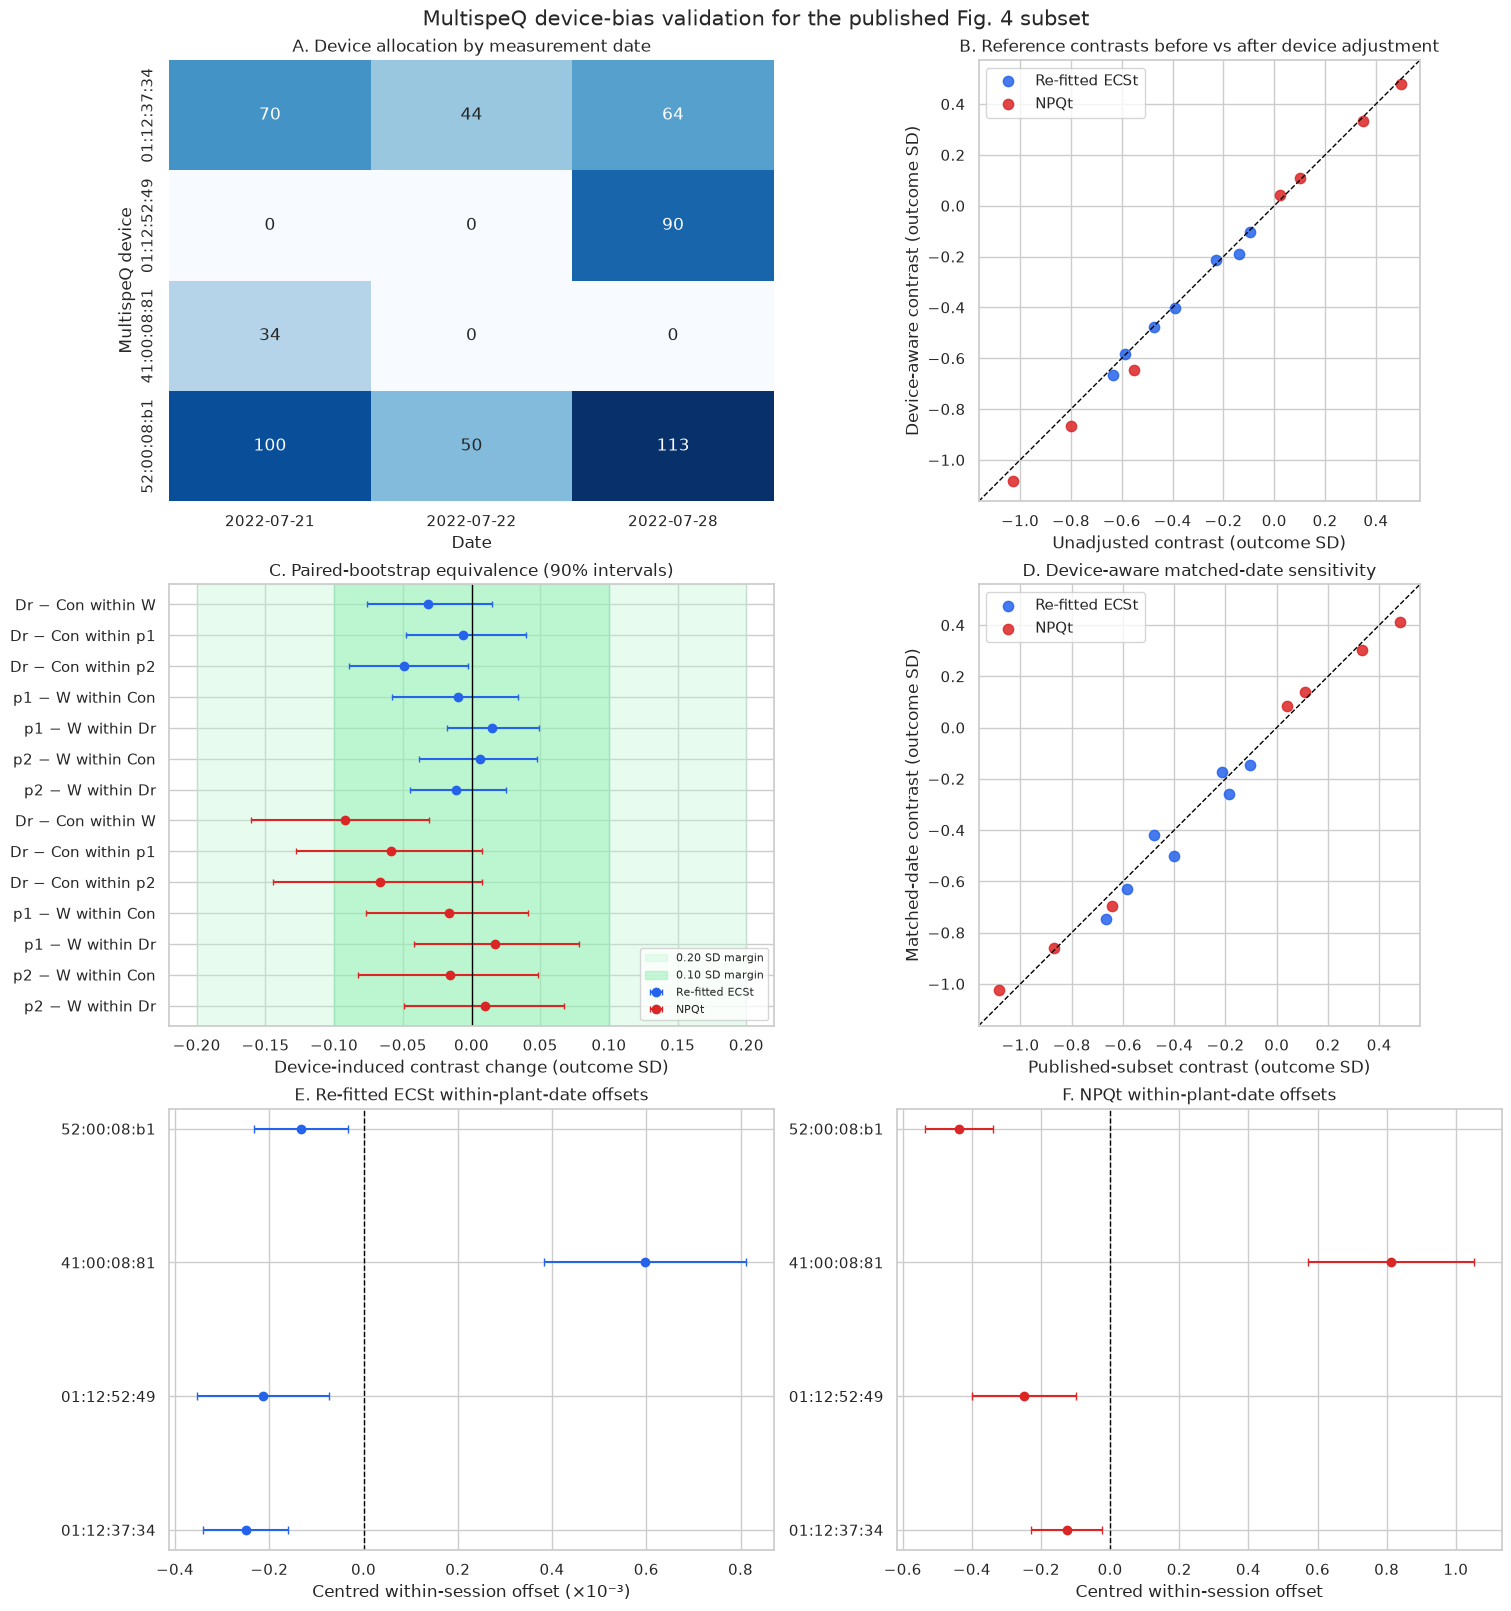

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(15, 16), constrained_layout=True)

sns.heatmap(device_by_date, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0, 0])
axes[0, 0].set_title("A. Device allocation by measurement date")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("MultispeQ device")

ax = axes[0, 1]
palette = {"ECSt_calc": "#2563eb", "NPQt": "#dc2626"}
for outcome, group in contrast_comparison.groupby("outcome_unadjusted"):
    outcome_sd = analysis[outcome].std()
    ax.scatter(
        group["estimate_unadjusted"] / outcome_sd,
        group["estimate_device_aware"] / outcome_sd,
        s=55, alpha=0.85, label=OUTCOMES[outcome], color=palette[outcome],
    )
limits = np.asarray(ax.get_xlim() + ax.get_ylim())
low, high = limits.min(), limits.max()
ax.plot([low, high], [low, high], color="black", ls="--", lw=1)
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Unadjusted contrast (outcome SD)")
ax.set_ylabel("Device-aware contrast (outcome SD)")
ax.set_title("B. Reference contrasts before vs after device adjustment")
ax.legend(frameon=True)

ax = axes[1, 0]
plot_equivalence = equivalence.copy()
plot_equivalence["ci90_low_sd"] = plot_equivalence["ci90_low"] / plot_equivalence["outcome"].map(FROZEN_SD)
plot_equivalence["ci90_high_sd"] = plot_equivalence["ci90_high"] / plot_equivalence["outcome"].map(FROZEN_SD)
plot_equivalence = plot_equivalence.sort_values(["outcome", "contrast"]).reset_index(drop=True)
y = np.arange(len(plot_equivalence))
for outcome, group in plot_equivalence.groupby("outcome"):
    positions = group.index.to_numpy()
    ax.errorbar(
        group["delta_sd"], positions,
        xerr=np.vstack([
            group["delta_sd"] - group["ci90_low_sd"],
            group["ci90_high_sd"] - group["delta_sd"],
        ]),
        fmt="o", capsize=2, color=palette[outcome], label=OUTCOMES[outcome],
    )
ax.axvspan(-0.2, 0.2, color="#bbf7d0", alpha=0.35, label="0.20 SD margin")
ax.axvspan(-0.1, 0.1, color="#86efac", alpha=0.45, label="0.10 SD margin")
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y, plot_equivalence["contrast"])
ax.invert_yaxis()
ax.set_xlabel("Device-induced contrast change (outcome SD)")
ax.set_title("C. Paired-bootstrap equivalence (90% intervals)")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1, 1]
matched_plot = matched_device_aware.copy()
for outcome, group in matched_plot.groupby("outcome"):
    ax.scatter(
        group["estimate_reference"] / FROZEN_SD[outcome],
        group["estimate_matched"] / FROZEN_SD[outcome],
        s=55, alpha=0.85, label=OUTCOMES[outcome], color=palette[outcome],
    )
limits = np.asarray(ax.get_xlim() + ax.get_ylim())
low, high = limits.min(), limits.max()
ax.plot([low, high], [low, high], color="black", ls="--", lw=1)
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Published-subset contrast (outcome SD)")
ax.set_ylabel("Matched-date contrast (outcome SD)")
ax.set_title("D. Device-aware matched-date sensitivity")
ax.legend(frameon=True)

for ax, outcome, scale, panel in [
    (axes[2, 0], "ECSt_calc", 1000, "E"),
    (axes[2, 1], "NPQt", 1, "F"),
]:
    plot_data = session_offsets.loc[session_offsets["outcome"] == outcome].copy()
    plot_data = plot_data.set_index("device_id").loc[category_orders["device_id"]].reset_index()
    y = np.arange(len(plot_data))
    x = plot_data["offset"].to_numpy() * scale
    xerr = np.vstack([
        (plot_data["offset"] - plot_data["ci_low"]).to_numpy() * scale,
        (plot_data["ci_high"] - plot_data["offset"]).to_numpy() * scale,
    ])
    ax.errorbar(x, y, xerr=xerr, fmt="o", color=palette[outcome], capsize=3)
    ax.axvline(0, color="black", lw=1, ls="--")
    ax.set_yticks(y, plot_data["device_id"])
    ax.set_xlabel("Centred within-session offset" + (" (×10⁻³)" if outcome == "ECSt_calc" else ""))
    ax.set_title(f"{panel}. {OUTCOMES[outcome]} within-plant-date offsets")

fig.suptitle("MultispeQ device-bias validation for the published Fig. 4 subset", fontsize=15)
figure_path = OUTPUT_DIR / "device_bias_validation.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()


In [11]:
device_summary.to_csv(OUTPUT_DIR / "device_bias_summary.csv", index=False)
device_offsets.to_csv(OUTPUT_DIR / "device_bias_offsets.csv", index=False)
contrasts.to_csv(OUTPUT_DIR / "device_bias_contrasts.csv", index=False)
contrast_comparison.to_csv(OUTPUT_DIR / "device_bias_contrast_comparison.csv", index=False)
sensitivity_contrasts.to_csv(OUTPUT_DIR / "device_bias_sensitivity.csv", index=False)
equivalence.to_csv(OUTPUT_DIR / "device_bias_equivalence.csv", index=False)
matched_contrasts.to_csv(OUTPUT_DIR / "device_bias_matched_date_contrasts.csv", index=False)
matched_summary.to_csv(OUTPUT_DIR / "device_bias_matched_date_summary.csv", index=False)
matched_comparison.to_csv(OUTPUT_DIR / "device_bias_matched_date_comparison.csv", index=False)
session_summary.to_csv(OUTPUT_DIR / "device_bias_session_summary.csv", index=False)
session_offsets.to_csv(OUTPUT_DIR / "device_bias_session_offsets.csv", index=False)
bridge_stability.to_csv(OUTPUT_DIR / "device_bias_bridge_stability.csv", index=False)
adjusted_values.to_parquet(PROCESSED_DIR / "fig4_device_adjusted.parquet", index=False)
(OUTPUT_DIR / "device_bias_validation.md").write_text(
    summary_markdown + "\n", encoding="utf-8"
)

print("Wrote:")
for path in [
    figure_path,
    OUTPUT_DIR / "device_bias_summary.csv",
    OUTPUT_DIR / "device_bias_offsets.csv",
    OUTPUT_DIR / "device_bias_contrasts.csv",
    OUTPUT_DIR / "device_bias_contrast_comparison.csv",
    OUTPUT_DIR / "device_bias_sensitivity.csv",
    OUTPUT_DIR / "device_bias_equivalence.csv",
    OUTPUT_DIR / "device_bias_matched_date_contrasts.csv",
    OUTPUT_DIR / "device_bias_matched_date_summary.csv",
    OUTPUT_DIR / "device_bias_matched_date_comparison.csv",
    OUTPUT_DIR / "device_bias_session_summary.csv",
    OUTPUT_DIR / "device_bias_session_offsets.csv",
    OUTPUT_DIR / "device_bias_bridge_stability.csv",
    OUTPUT_DIR / "device_bias_validation.md",
    PROCESSED_DIR / "fig4_device_adjusted.parquet",
]:
    print(" -", path.relative_to(ROOT))


Wrote:
 - outputs/device_bias_validation.png
 - outputs/device_bias_summary.csv
 - outputs/device_bias_offsets.csv
 - outputs/device_bias_contrasts.csv
 - outputs/device_bias_contrast_comparison.csv
 - outputs/device_bias_sensitivity.csv
 - outputs/device_bias_equivalence.csv
 - outputs/device_bias_matched_date_contrasts.csv
 - outputs/device_bias_matched_date_summary.csv
 - outputs/device_bias_matched_date_comparison.csv
 - outputs/device_bias_session_summary.csv
 - outputs/device_bias_session_offsets.csv
 - outputs/device_bias_bridge_stability.csv
 - outputs/device_bias_validation.md
 - data/processed/fig4_device_adjusted.parquet


## Interpretation limits

- This is a robustness analysis of this experiment, not a laboratory calibration against a certified reference.
- Device, operator, time, leaf, and other unrecorded handling effects may remain entangled. The term “device effect” means a systematic association with device identity after the recorded controls.
- Two devices were used on only one date. The main model includes date, and the restricted cross-date-device analysis checks that the conclusion is not driven solely by those devices.
- Control includes a 22 July session without a concurrent Drought group. The matched-date analysis therefore uses 21 and 28 July as a supporting sensitivity check and detects two changed borderline FDR calls.
- The two bridge devices have date-dependent relative offsets for both outcomes, so a single additive device correction should not be interpreted as a universal calibration constant.
- Repeated observations are handled with plant-clustered standard errors. The number of plants, not the number of individual measurements, is the relevant independent replication level.
- Multiple biological contrasts are controlled at 5% FDR separately for each outcome and model, with an additional across-all-14 correction reported. Equivalence is evaluated separately using pre-specified margins and paired plant-cluster bootstrap intervals.